# Big Data Applications — Forecasting & Machine Learning Analysis
**Data Scientist / Jupyter Notebook**

This notebook combines data profiling, exploratory visualizations, forecasting, and a broad benchmark of machine-learning models on the firm-year dataset.

**Important methodology:** the data are a panel of firms observed across years, not a single long daily/monthly time series. The main forecast task predicts a firm's **next observed year's** `TD` and `MD` using information from its current record. A chronological split is used to reduce look-ahead bias. The annual aggregate forecast is included as an exploratory demonstration, but there are only about ten annual observations, which is too little to confidently compare complex time-series models.

This notebook evaluates a broad selection of common models; it is not literally every ML algorithm. Model availability depends on the installed Python environment. No model should be selected solely by its training score.

## 1. Setup and imports

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn statsmodels xgboost lightgbm catboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 4.9 MB/s eta 0:00:10
   -- ------------------------------------- 3.4/48.9 MB 7.7 MB/s eta 0:00:06
   ---- ----------------------------------- 6.0/48.9 MB 9.4 MB/s eta 0:00:05
   ------- -------------------------------- 9.2/48.9 MB 10.9 MB/s eta 0:00:04
   --------- ------------------------------ 11.3/48.9 MB 11.5 MB/s eta 0:00:04
   ------------ --------------------------- 15.7/48.9 MB 12.6 MB/s eta 0:00:03
   --------------- ------------------------ 19.1/48.9 MB 12.9 MB/s eta 0:00:03
   ----------------- ---------------------- 21.2/48.9 MB 12.5 MB/s eta 0:00:03
   ------------------- -------------------- 23.9/48.9 MB 12.5 MB/s eta 0:00:03
   --------------------- ------------------ 26.5/48.9 MB 12.5 MB/s eta 0:00:02
   ----------------------- ---------------- 29.4/48.9 MB 12.6 MB/s eta 0:00:0

In [2]:
# If a package is missing, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor,
    BayesianRidge, SGDRegressor, PoissonRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, AdaBoostRegressor, RandomForestRegressor,
    VotingRegressor, StackingRegressor, RandomForestRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

## 2. Load the data

In [3]:
# Keep the CSV in the same folder as this notebook, or update CSV_PATH.
CSV_PATH = Path("Big_Data_Applications_clean(1).csv")
if not CSV_PATH.exists():
    # Also support the original filename if you rename/copy it.
    alternate = Path("Big_Data_Applications_clean.csv")
    if alternate.exists():
        CSV_PATH = alternate
    else:
        raise FileNotFoundError(
            "CSV file not found. Place Big_Data_Applications_clean(1).csv "
            "in the same folder as this notebook or update CSV_PATH."
        )

df = pd.read_csv(CSV_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 21,203 | Columns: 26


,firm_code,firm_code_str,year,province,province_name,region,industry_code,sector,TD,MD,BDA,IC,ADC,GI,GP,TD_std,MD_std,log_TD,log_MD,TD_share,TD_growth,MD_growth,BDA_change,n_years_observed,first_year,last_year
0,8,8,2015,110000,Beijing,East,C37,C,119,890,4,0,-1,0,1,0,0,4.787492,6.792344,0.1337,NaN,NaN,NaN,9,2015,2023
1,8,8,2016,110000,Beijing,East,C37,C,98,691,4,1,-1,0,2,0,0,4.595120,6.539586,0.1418,-0.1765,-0.2236,0.0,9,2015,2023
2,8,8,2017,110000,Beijing,East,C37,C,133,978,5,1,-1,0,2,0,0,4.897840,6.886532,0.1360,0.3571,0.4153,1.0,9,2015,2023
3,8,8,2018,110000,Beijing,East,C37,C,97,722,5,1,-1,0,2,0,0,4.584967,6.583409,0.1343,-0.2707,-0.2618,0.0,9,2015,2023
4,8,8,2019,110000,Beijing,East,C37,C,173,1309,5,1,-1,0,1,0,0,5.159055,7.177782,0.1322,0.7835,0.8130,0.0,9,2015,2023


## 3. Data quality and descriptive profile

In [4]:
print("Dataset shape:", df.shape)
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False))

print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)

Dataset shape: (21203, 26)


,dtype,missing_count,missing_pct,n_unique
BDA_change,float64,3514,16.57,8
MD_growth,float64,3514,16.57,11280
TD_growth,float64,3514,16.57,6181
firm_code,int64,0,0.00,3514
firm_code_str,int64,0,0.00,3514
first_year,int64,0,0.00,10
n_years_observed,int64,0,0.00,10
TD_share,float64,0,0.00,659
log_MD,float64,0,0.00,3251
log_TD,float64,0,0.00,1007


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
firm_code,21203.0,NaN,NaN,NaN,319611.318021,272861.579349,8.0,2540.0,300527.0,600893.0,873726.0
firm_code_str,21203.0,NaN,NaN,NaN,319611.318021,272861.579349,8.0,2540.0,300527.0,600893.0,873726.0
year,21203.0,NaN,NaN,NaN,2019.405603,2.792613,2014.0,2017.0,2020.0,2022.0,2023.0
province,21203.0,NaN,NaN,NaN,356089.704287,111319.511528,110000.0,320000.0,340000.0,440000.0,650000.0
province_name,21203,31,Guangdong,3596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,21203,4,East,15091,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry_code,21203,32,C39,3325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,21203,4,C,21200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TD,21203.0,NaN,NaN,NaN,121.375324,265.142174,1.0,18.0,43.0,104.0,1942.0
MD,21203.0,NaN,NaN,NaN,883.702919,1950.089379,8.0,129.0,313.0,760.0,14499.0


In [5]:
if "year" in df:
    print("Year range:", df["year"].min(), "to", df["year"].max())
    print("Firm codes:", df["firm_code"].nunique() if "firm_code" in df else "firm_code not found")
    display(df.groupby("year").size().rename("observations").to_frame())
if "TD" in df and "MD" in df:
    display(df[["TD", "MD", "BDA", "IC", "ADC", "GI", "GP"]].describe().T
            if set(["BDA","IC","ADC","GI","GP"]).issubset(df.columns)
            else df[["TD","MD"]].describe().T)

Year range: 2014 to 2023
Firm codes: 3514


,observations
year,
2014,1253
2015,1346
2016,1472
2017,1782
2018,1921
2019,2035
2020,2318
2021,2724
2022,3024


,count,mean,std,min,25%,50%,75%,max
TD,21203.0,121.375324,265.142174,1.0,18.0,43.0,104.0,1942.0
MD,21203.0,883.702919,1950.089379,8.0,129.0,313.0,760.0,14499.0
BDA,21203.0,4.274112,0.551766,1.0,4.0,4.0,5.0,7.0
IC,21203.0,0.242371,0.445049,0.0,0.0,0.0,0.0,2.0
ADC,21203.0,-1.012593,0.334595,-2.0,-1.0,-1.0,-1.0,0.0
GI,21203.0,0.058812,0.235279,0.0,0.0,0.0,0.0,1.0
GP,21203.0,1.805641,1.361955,0.0,1.0,2.0,3.0,8.0


## 4. Exploratory visualizations

The following plots are generated from the actual CSV. Categorical charts show record composition, not necessarily the distribution of unique firms.

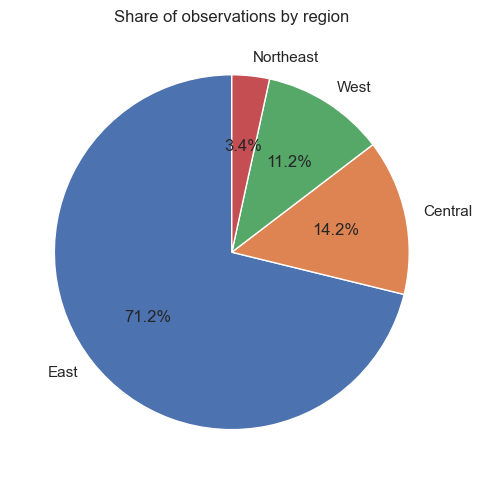

In [23]:
# 4.1 Pie chart: observations by region
if "region" in df:
    region_counts = df["region"].fillna("Missing").value_counts()
    plt.figure(figsize=(8, 5))
    plt.pie(region_counts.values, labels=region_counts.index, autopct="%1.1f%%", startangle=90)
    plt.title("Share of observations by region")
    plt.tight_layout()
    plt.show()

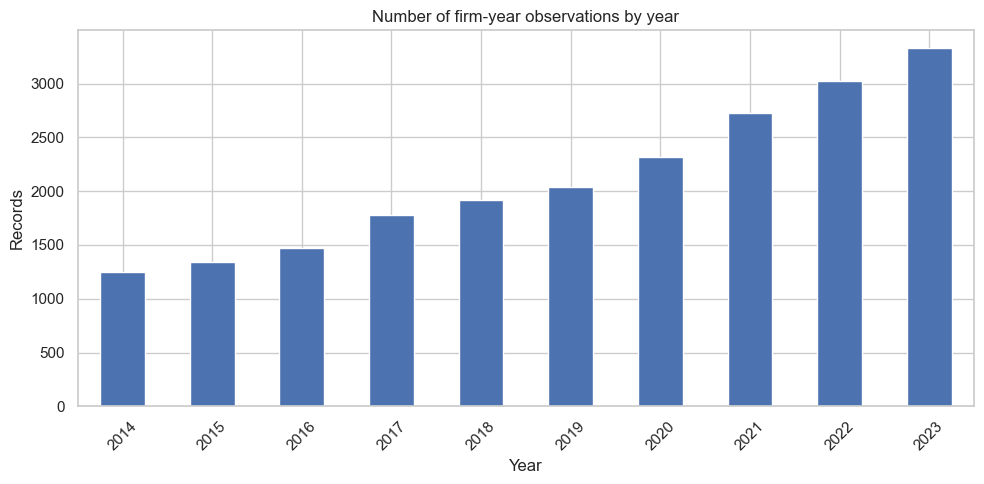

In [7]:
# 4.2 Bar chart: number of records by year
if "year" in df:
    yearly_n = df.groupby("year").size()
    ax = yearly_n.plot(kind="bar", figsize=(10, 5))
    ax.set(title="Number of firm-year observations by year", xlabel="Year", ylabel="Records")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

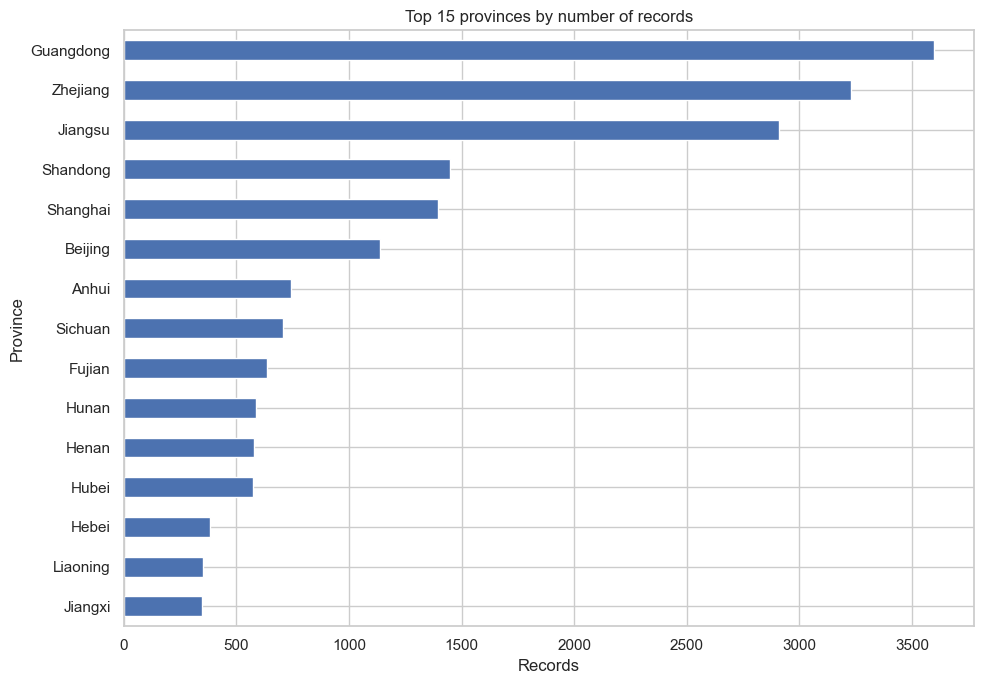

In [8]:
# 4.3 Horizontal bar chart: most represented provinces
if "province_name" in df:
    province_counts = df["province_name"].fillna("Missing").value_counts().head(15).sort_values()
    ax = province_counts.plot(kind="barh", figsize=(10, 7))
    ax.set(title="Top 15 provinces by number of records", xlabel="Records", ylabel="Province")
    plt.tight_layout()
    plt.show()

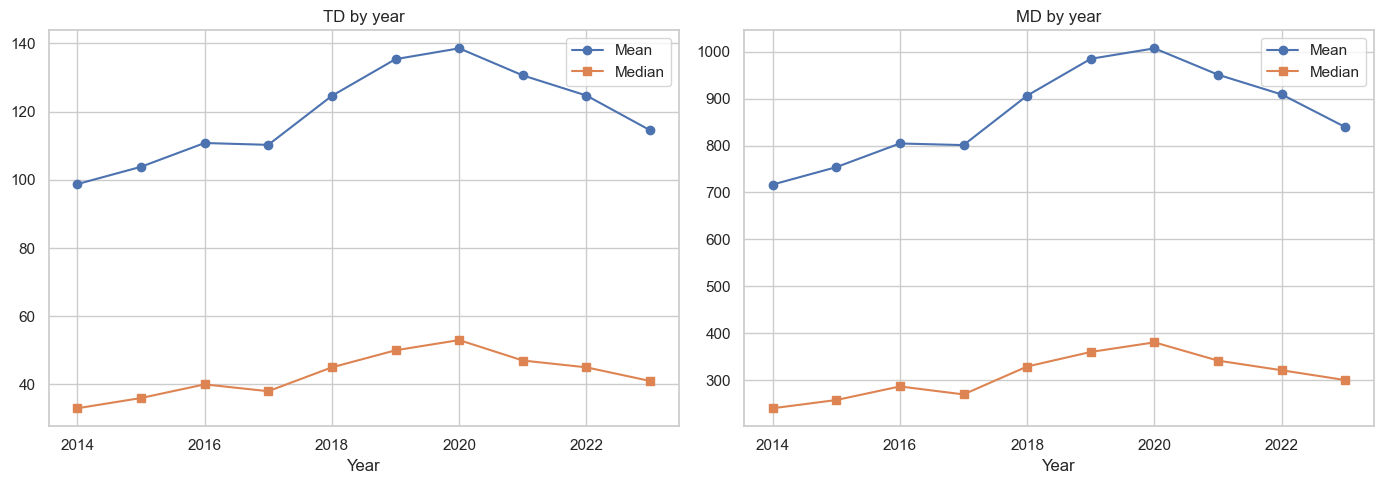

In [9]:
# 4.4 Line chart: annual mean and median of TD and MD
if {"year", "TD", "MD"}.issubset(df.columns):
    annual = df.groupby("year")[["TD", "MD"]].agg(["mean", "median"])
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    annual[("TD", "mean")].plot(ax=axes[0], marker="o", label="Mean")
    annual[("TD", "median")].plot(ax=axes[0], marker="s", label="Median")
    axes[0].set_title("TD by year"); axes[0].set_xlabel("Year"); axes[0].legend()
    annual[("MD", "mean")].plot(ax=axes[1], marker="o", label="Mean")
    annual[("MD", "median")].plot(ax=axes[1], marker="s", label="Median")
    axes[1].set_title("MD by year"); axes[1].set_xlabel("Year"); axes[1].legend()
    plt.tight_layout(); plt.show()

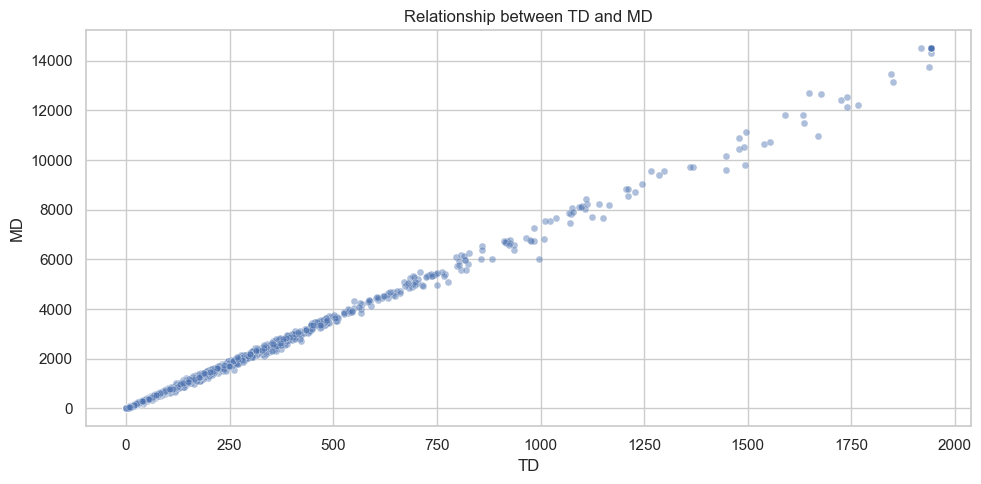

Pearson correlation TD vs MD: 0.999272569103101


In [10]:
# 4.5 Scatter plot: TD vs MD (sample if dataset is large)
if {"TD", "MD"}.issubset(df.columns):
    plot_df = df[["TD", "MD"]].dropna()
    if len(plot_df) > 5000:
        plot_df = plot_df.sample(5000, random_state=RANDOM_STATE)
    sns.scatterplot(data=plot_df, x="TD", y="MD", alpha=0.45, s=25)
    plt.title("Relationship between TD and MD")
    plt.tight_layout(); plt.show()
    print("Pearson correlation TD vs MD:", df[["TD", "MD"]].corr().iloc[0,1])

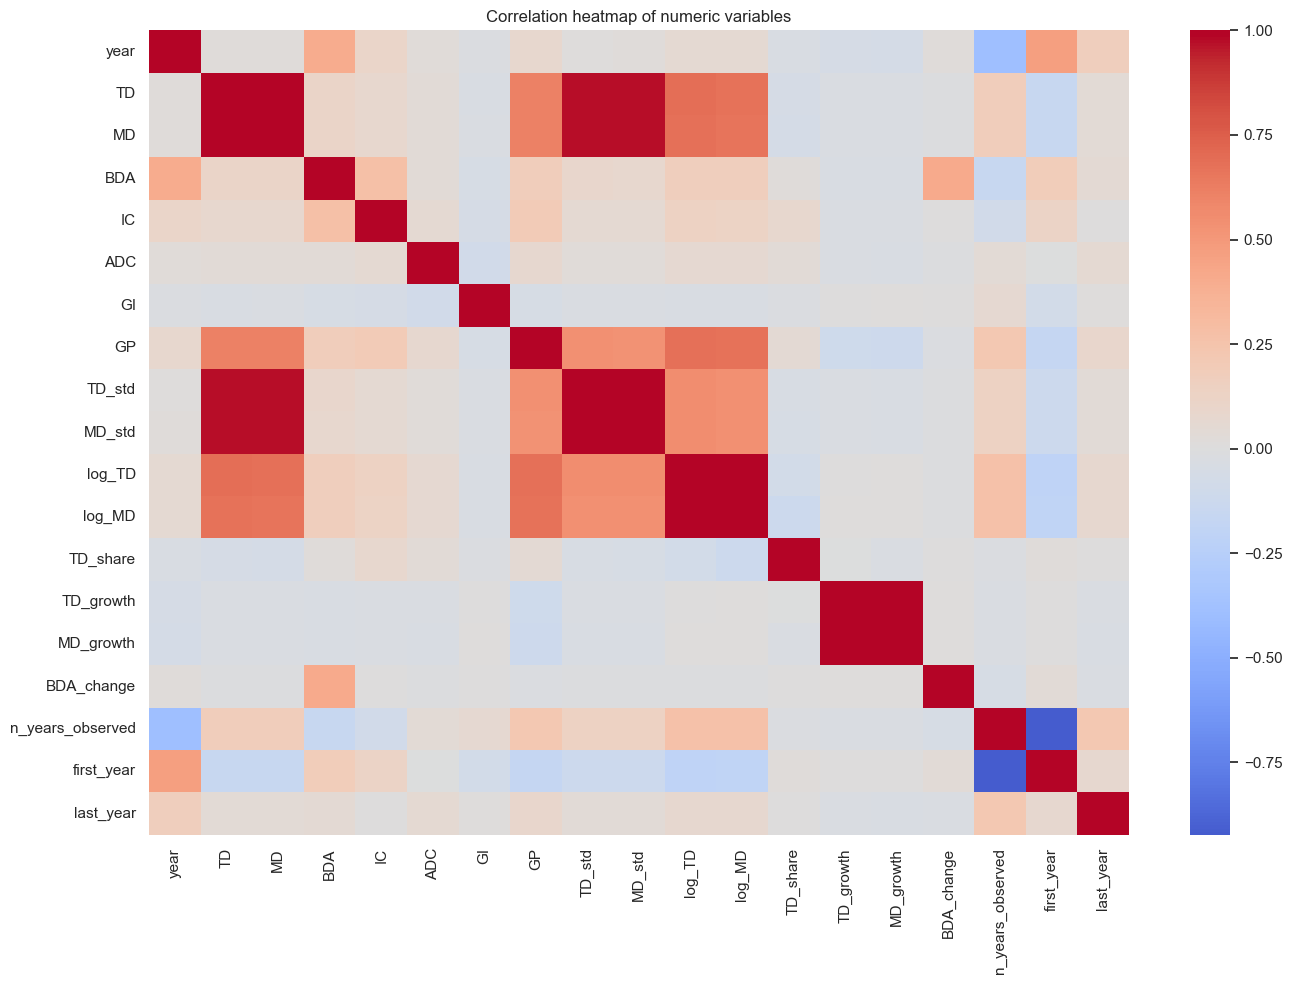

In [11]:
# 4.6 Heatmap: numeric correlation matrix
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    # Exclude ID-like fields from this plot where possible, to keep it readable.
    heat_cols = [c for c in numeric_df.columns if c not in ["firm_code", "firm_code_str", "province"]]
    corr = df[heat_cols].corr(numeric_only=True)
    plt.figure(figsize=(14, 5))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
    plt.title("Correlation heatmap of numeric variables")
    plt.tight_layout(); plt.show()

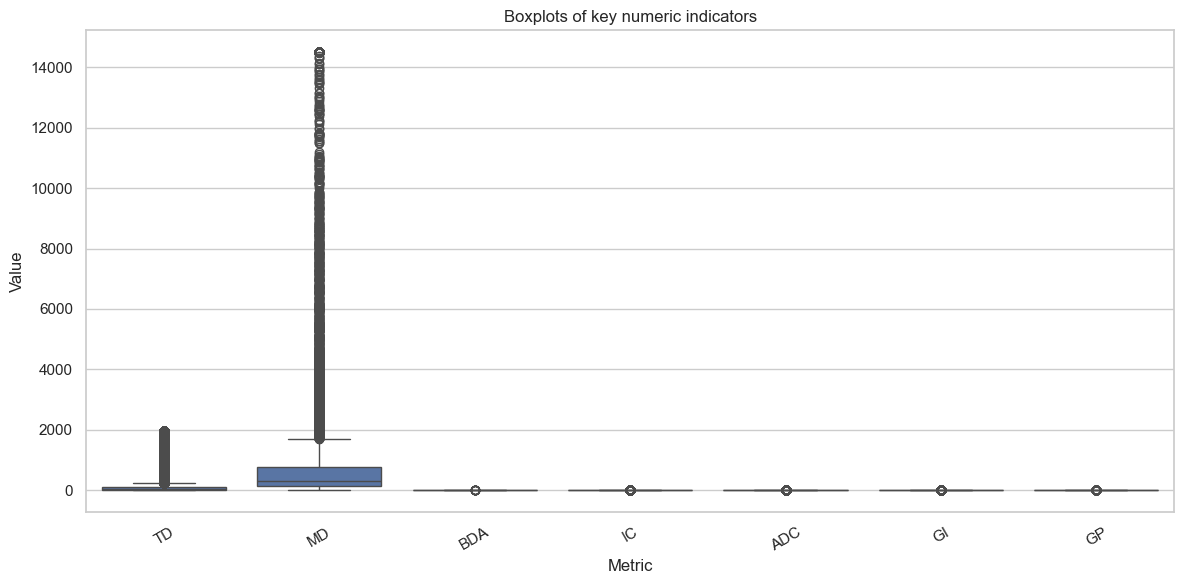

In [12]:
# 4.7 Boxplots: distributions of key metrics
metrics = [c for c in ["TD", "MD", "BDA", "IC", "ADC", "GI", "GP"] if c in df.columns]
if metrics:
    long_metrics = df[metrics].melt(var_name="Metric", value_name="Value")
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=long_metrics, x="Metric", y="Value")
    plt.title("Boxplots of key numeric indicators")
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()

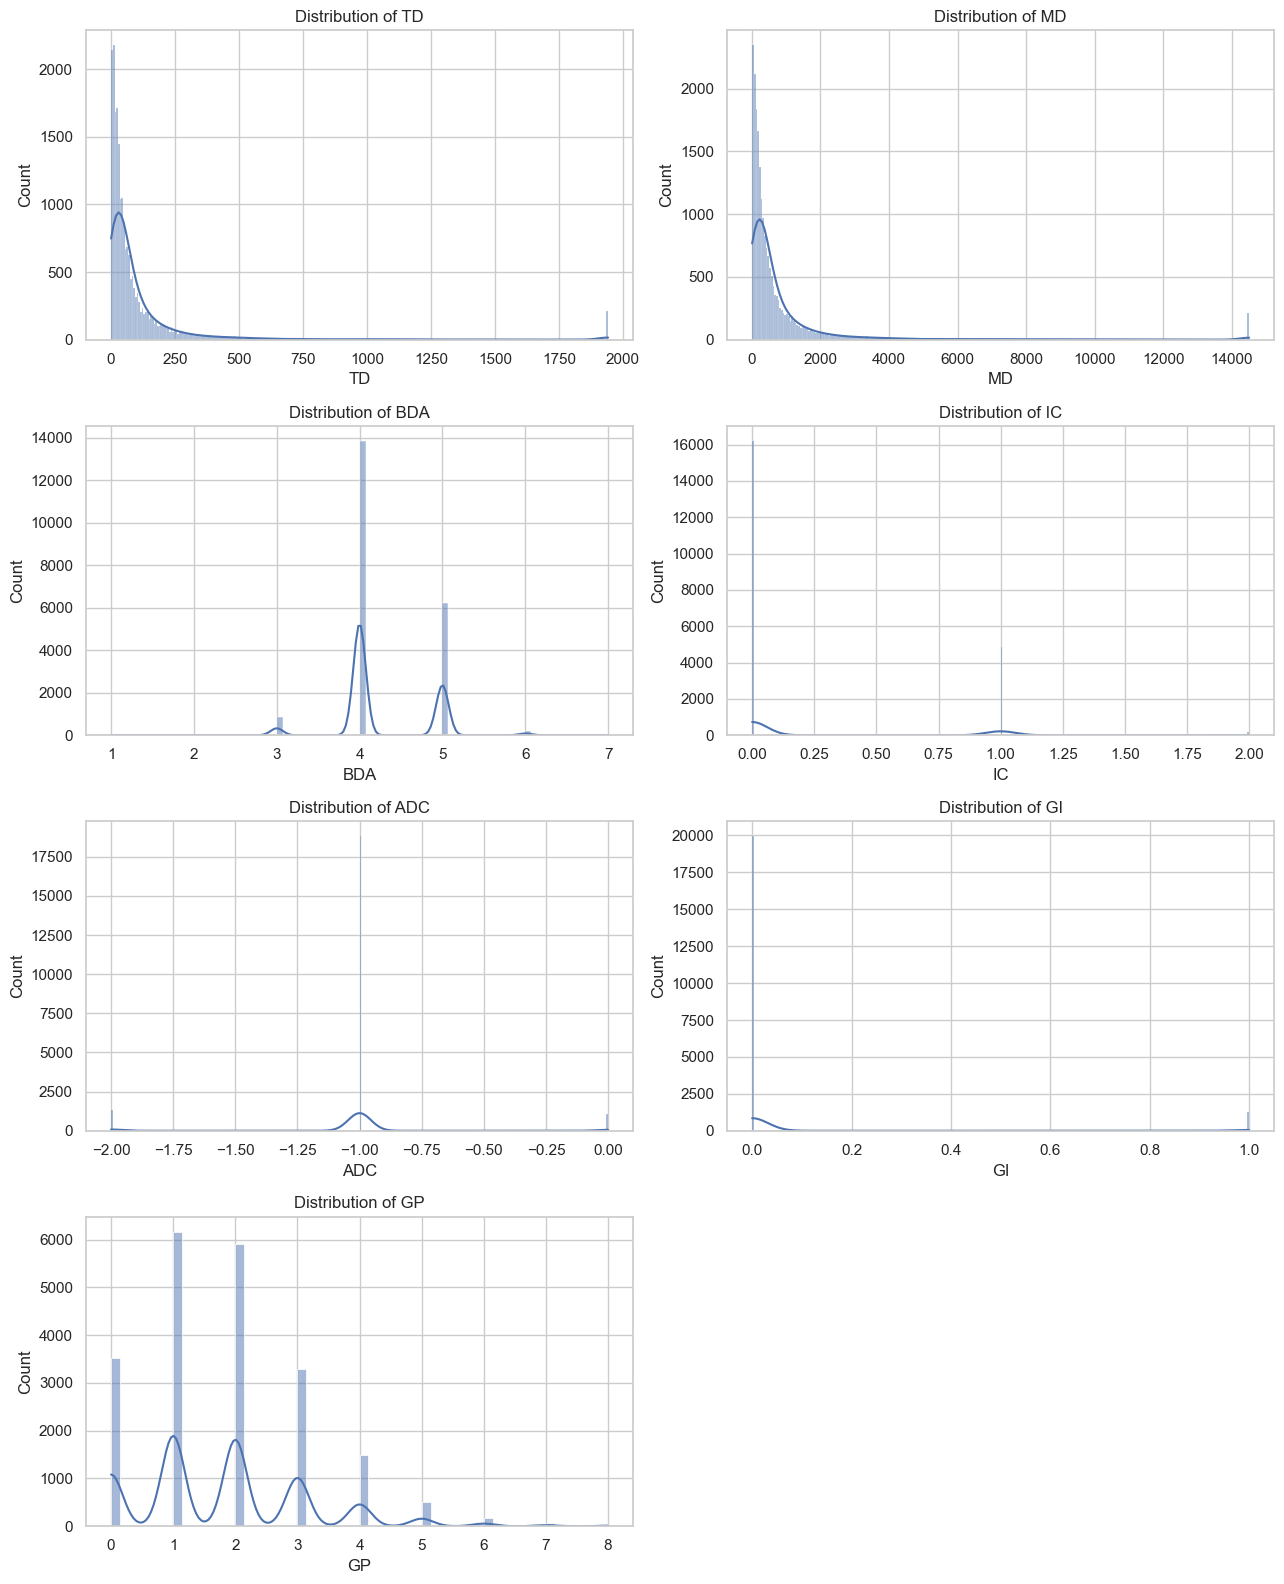

In [13]:
# 4.8 Histograms: distributions of key metrics
metrics = [c for c in ["TD", "MD", "BDA", "IC", "ADC", "GI", "GP"] if c in df.columns]
if metrics:
    ncols = 2
    nrows = int(np.ceil(len(metrics) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4*nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, metrics):
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"Distribution of {col}")
    for ax in axes[len(metrics):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

## 5. Forecast design and leakage prevention

The prediction target is the **next observed row for the same firm**. For example, a 2021 record can be used to predict the firm's 2022 `TD`. This is different from forecasting a firm's value in a year where it has no record.

- `future_TD` and `future_MD` are generated by shifting targets within each firm.
- Rows without a future observed year are excluded from supervised training.
- The split is chronological: earlier years train the models and later years test them.
- Identifiers and direct future/summary metadata are excluded from predictors.
- Current-year `TD`/`MD` may be used to predict the next year's values, because they would be known at forecast time.
- Treat scores cautiously if the dataset has selection bias, irregular firm coverage, or firm-level dependence.

## 6. Create next-year targets and features

In [14]:
data = df.copy()
if "firm_code" not in data.columns or "year" not in data.columns:
    raise ValueError("Forecasting requires firm_code and year columns.")
data = data.sort_values(["firm_code", "year"]).reset_index(drop=True)

# Only predict when the next record for a firm is exactly one calendar year later.
data["next_year"] = data.groupby("firm_code")["year"].shift(-1)
data["future_TD"] = data.groupby("firm_code")["TD"].shift(-1) if "TD" in data else np.nan
data["future_MD"] = data.groupby("firm_code")["MD"].shift(-1) if "MD" in data else np.nan
data.loc[data["next_year"] != data["year"] + 1, ["future_TD", "future_MD"]] = np.nan

print("Rows with next-year TD target:", data["future_TD"].notna().sum())
print("Rows with next-year MD target:", data["future_MD"].notna().sum())
display(data[["firm_code", "year", "next_year", "TD", "future_TD", "MD", "future_MD"]].head(10))

Rows with next-year TD target: 17120
Rows with next-year MD target: 17120


,firm_code,year,next_year,TD,future_TD,MD,future_MD
0,8,2015,2016.0,119,98.0,890,691.0
1,8,2016,2017.0,98,133.0,691,978.0
2,8,2017,2018.0,133,97.0,978,722.0
3,8,2018,2019.0,97,173.0,722,1309.0
4,8,2019,2020.0,173,157.0,1309,1144.0
5,8,2020,2021.0,157,105.0,1144,758.0
6,8,2021,2022.0,105,207.0,758,1531.0
7,8,2022,2023.0,207,162.0,1531,1211.0
8,8,2023,NaN,162,NaN,1211,NaN
9,10,2014,NaN,7,NaN,55,NaN


## 7. Build a broad machine-learning model benchmark

In [15]:
# Optional model families: XGBoost, LightGBM and CatBoost are included only if installed.
models = {
    "Dummy mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000),
    "Bayesian Ridge": BayesianRidge(),
    "Huber Regressor": HuberRegressor(max_iter=500),
    "SGD Regressor": SGDRegressor(random_state=RANDOM_STATE, max_iter=2000, tol=1e-3),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE, min_samples_leaf=5),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2),
    "Extra Trees": ExtraTreesRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostRegressor(random_state=RANDOM_STATE, n_estimators=100),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "Support Vector Regression": SVR(C=10, epsilon=0.1),
    "MLP Neural Network": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE)
}

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=250, max_depth=5, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=-1
    )
except Exception as e:
    print("XGBoost skipped:", e)

try:
    from lightgbm import LGBMRegressor
    models["LightGBM"] = LGBMRegressor(n_estimators=250, learning_rate=0.05, random_state=RANDOM_STATE, verbosity=-1)
except Exception as e:
    print("LightGBM skipped:", e)

try:
    from catboost import CatBoostRegressor
    models["CatBoost"] = CatBoostRegressor(iterations=250, depth=6, learning_rate=0.05, verbose=False, random_seed=RANDOM_STATE)
except Exception as e:
    print("CatBoost skipped:", e)

print(f"Models available: {len(models)}")
print(", ".join(models.keys()))

Models available: 20
Dummy mean baseline, Linear Regression, Ridge, Lasso, ElasticNet, Bayesian Ridge, Huber Regressor, SGD Regressor, Decision Tree, Random Forest, Extra Trees, Gradient Boosting, Hist Gradient Boosting, AdaBoost, K-Nearest Neighbors, Support Vector Regression, MLP Neural Network, XGBoost, LightGBM, CatBoost


In [16]:
# Predictor selection: avoid IDs, targets, next-year values, and end-of-panel metadata.
excluded = {
    "firm_code", "firm_code_str", "future_TD", "future_MD", "next_year",
    "first_year", "last_year", "n_years_observed"
}
feature_cols = [c for c in data.columns if c not in excluded]
# Also remove variables that directly encode a target-derived future or duplicate IDs.
feature_cols = [c for c in feature_cols if c not in ["TD_std", "MD_std"]]

# Keep year and current measurements as valid forecast-time features.
X_all = data[feature_cols].copy()
# Convert integer-coded province to categorical text to avoid treating province codes as continuous values.
for col in ["province", "industry_code", "sector", "province_name", "region"]:
    if col in X_all.columns:
        X_all[col] = X_all[col].astype("string")

categorical_features = X_all.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_features = [c for c in X_all.columns if c not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ],
    remainder="drop"
)
print("Number of features:", len(feature_cols))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Number of features: 19
Numeric features: ['year', 'TD', 'MD', 'BDA', 'IC', 'ADC', 'GI', 'GP', 'log_TD', 'log_MD', 'TD_share', 'TD_growth', 'MD_growth', 'BDA_change']
Categorical features: ['province', 'province_name', 'region', 'industry_code', 'sector']


## 8. Chronological train/test split and evaluation

In [17]:
max_year = int(data["year"].max())
# Hold out the last two source years for testing. Training uses only earlier years.
train_cutoff = max_year - 2
test_start = max_year - 1

def evaluate_forecast(target_col, target_name):
    work = data.loc[data[target_col].notna()].copy()
    train_mask = work["year"] <= train_cutoff
    test_mask = work["year"] >= test_start
    X_train = X_all.loc[work.index[train_mask]]
    y_train = work.loc[train_mask, target_col].astype(float)
    X_test = X_all.loc[work.index[test_mask]]
    y_test = work.loc[test_mask, target_col].astype(float)

    if len(X_train) == 0 or len(X_test) == 0:
        print(f"Not enough rows for {target_name}. Check the year coverage.")
        return None, None, None

    print(f"Target: {target_name} | train rows={len(X_train):,} through year {train_cutoff} | test rows={len(X_test):,} from year {test_start}")
    results, fitted, predictions = [], {}, {}
    for name, model in models.items():
        pipe = Pipeline([("preprocess", clone(preprocessor)), ("model", clone(model))])
        try:
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_test)
            results.append({
                "target": target_name, "model": name,
                "MAE": mean_absolute_error(y_test, pred),
                "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                "R2": r2_score(y_test, pred) if len(y_test) > 1 else np.nan
            })
            fitted[name] = pipe
            predictions[name] = pred
        except Exception as exc:
            print(f"Skipped {name} for {target_name}: {type(exc).__name__}: {exc}")
    result_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
    display(result_df)
    return result_df, fitted, (X_test, y_test, predictions)

results_TD, fitted_TD, test_TD = evaluate_forecast("future_TD", "Next-year TD")
results_MD, fitted_MD, test_MD = evaluate_forecast("future_MD", "Next-year MD")

Target: Next-year TD | train rows=14,140 through year 2021 | test rows=2,980 from year 2022
Skipped Bayesian Ridge for Next-year TD: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
Skipped Hist Gradient Boosting for Next-year TD: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.


,target,model,MAE,RMSE,R2
0,Next-year TD,MLP Neural Network,30.645483,65.974367,0.937854
1,Next-year TD,ElasticNet,31.979498,66.054685,0.937702
2,Next-year TD,Huber Regressor,29.889394,66.252787,0.937328
3,Next-year TD,XGBoost,31.163481,66.651175,0.936572
4,Next-year TD,CatBoost,31.131359,66.672148,0.936532
5,Next-year TD,Ridge,31.755563,66.963130,0.935977
6,Next-year TD,Lasso,31.642729,66.995168,0.935916
7,Next-year TD,Gradient Boosting,31.109646,67.046637,0.935817
8,Next-year TD,SGD Regressor,33.151215,67.081685,0.935750
9,Next-year TD,Linear Regression,31.728410,67.121104,0.935674


Target: Next-year MD | train rows=14,140 through year 2021 | test rows=2,980 from year 2022
Skipped Bayesian Ridge for Next-year MD: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
Skipped Hist Gradient Boosting for Next-year MD: TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.


,target,model,MAE,RMSE,R2
0,Next-year MD,Huber Regressor,218.561208,484.943130,0.938515
1,Next-year MD,MLP Neural Network,227.852457,488.657927,0.937569
2,Next-year MD,ElasticNet,230.759968,489.515400,0.937350
3,Next-year MD,Lasso,230.874204,489.667492,0.937311
4,Next-year MD,Linear Regression,230.974345,489.679252,0.937308
5,Next-year MD,Ridge,230.865445,490.040790,0.937215
6,Next-year MD,CatBoost,227.397265,491.907628,0.936736
7,Next-year MD,Gradient Boosting,228.318805,492.859802,0.936491
8,Next-year MD,XGBoost,227.952991,496.619043,0.935518
9,Next-year MD,SGD Regressor,238.446608,497.145953,0.935381


## 9. Compare model performance

,target,model,MAE,RMSE,R2
18,Next-year MD,Huber Regressor,218.561208,484.943130,0.938515
19,Next-year MD,MLP Neural Network,227.852457,488.657927,0.937569
20,Next-year MD,ElasticNet,230.759968,489.515400,0.937350
21,Next-year MD,Lasso,230.874204,489.667492,0.937311
22,Next-year MD,Linear Regression,230.974345,489.679252,0.937308
23,Next-year MD,Ridge,230.865445,490.040790,0.937215
24,Next-year MD,CatBoost,227.397265,491.907628,0.936736
25,Next-year MD,Gradient Boosting,228.318805,492.859802,0.936491
26,Next-year MD,XGBoost,227.952991,496.619043,0.935518
27,Next-year MD,SGD Regressor,238.446608,497.145953,0.935381


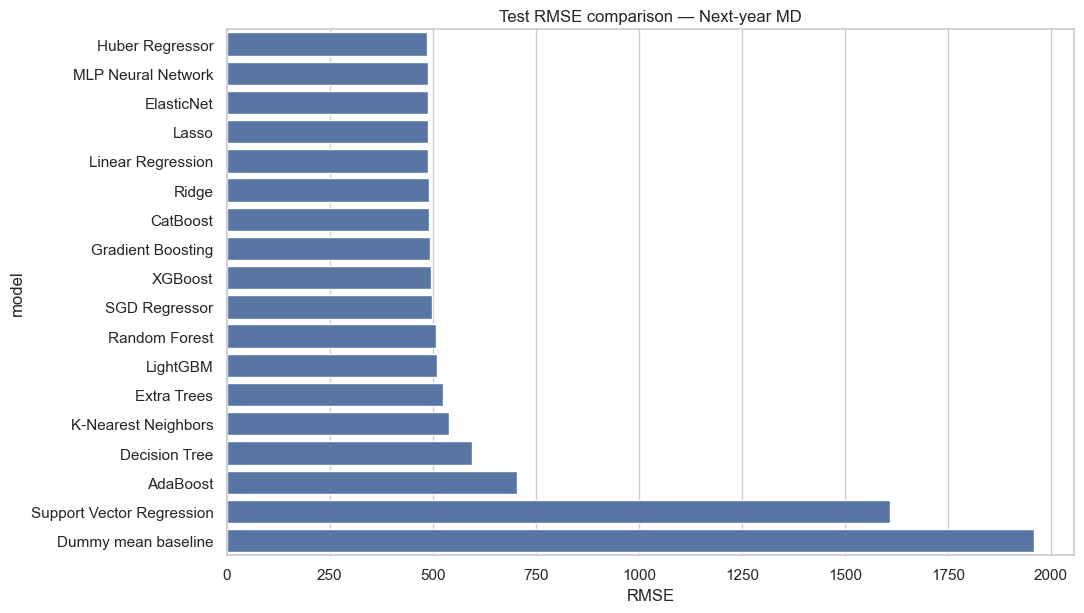

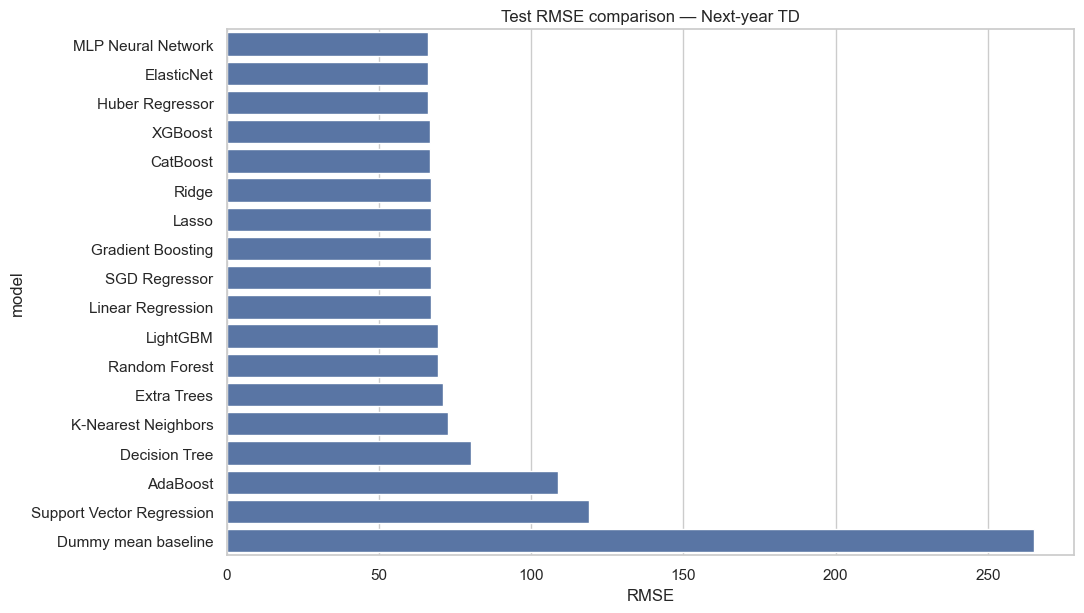

In [18]:
all_results = pd.concat([r for r in [results_TD, results_MD] if r is not None], ignore_index=True)
if not all_results.empty:
    display(all_results.sort_values(["target", "RMSE"]))
    for target_name, subset in all_results.groupby("target"):
        plot_data = subset.sort_values("RMSE")
        plt.figure(figsize=(11, max(5, 0.35*len(plot_data))))
        sns.barplot(data=plot_data, x="RMSE", y="model")
        plt.title(f"Test RMSE comparison — {target_name}")
        plt.tight_layout(); plt.show()

## 10. Actual vs predicted and residual diagnostics

Best by test RMSE for next-year TD: MLP Neural Network


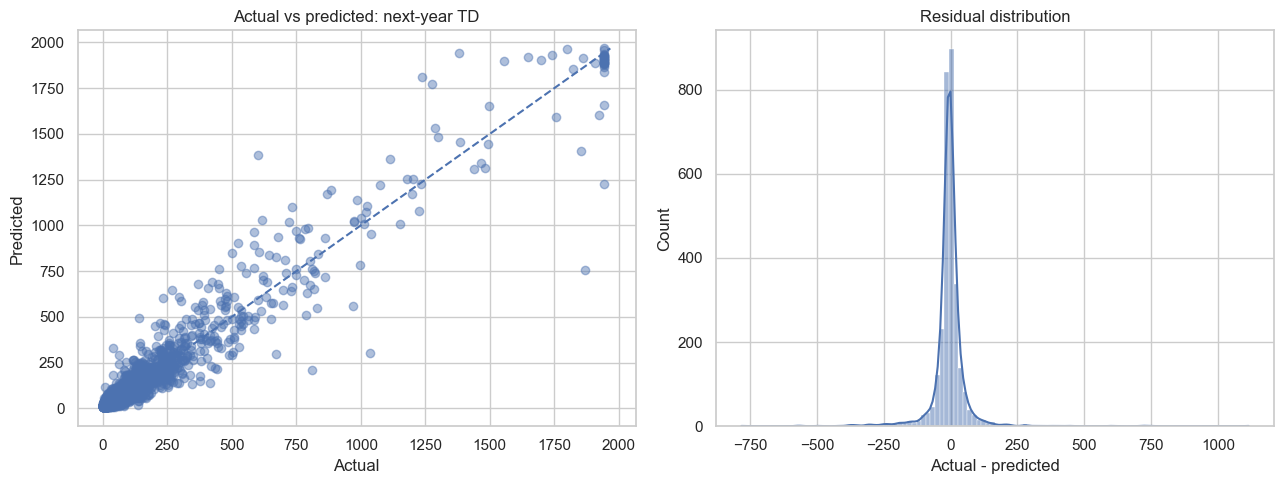

Best by test RMSE for next-year MD: Huber Regressor


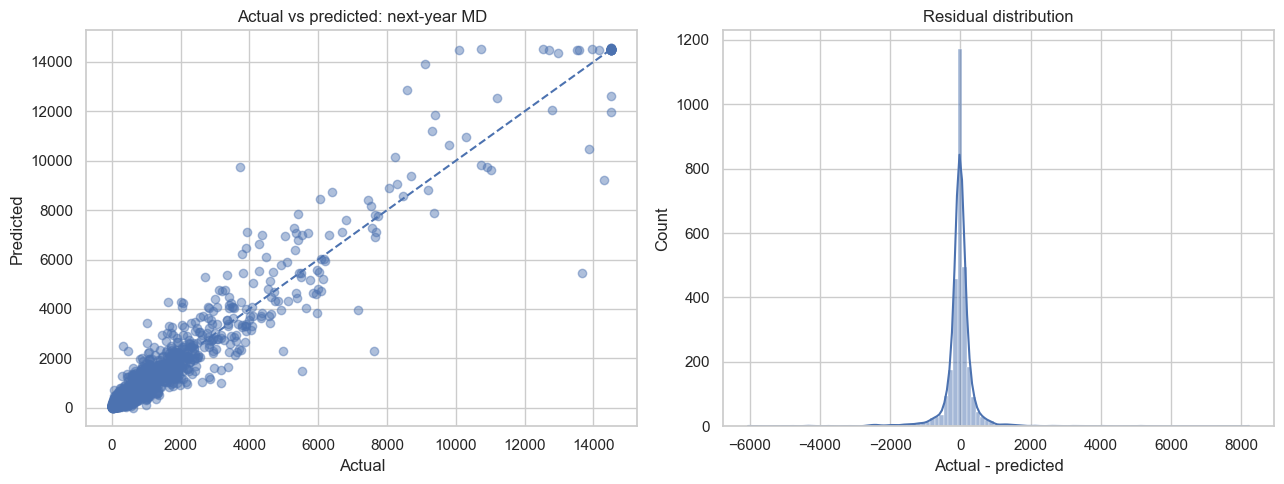

In [19]:
def plot_best_model(results, fitted_models, test_bundle, target_label):
    if results is None or results.empty or test_bundle is None:
        return
    best_name = results.iloc[0]["model"]
    X_test, y_test, pred_dict = test_bundle
    y_pred = pred_dict[best_name]
    print(f"Best by test RMSE for {target_label}: {best_name}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_test, y_pred, alpha=0.45)
    low = min(float(np.min(y_test)), float(np.min(y_pred)))
    high = max(float(np.max(y_test)), float(np.max(y_pred)))
    axes[0].plot([low, high], [low, high], linestyle="--")
    axes[0].set(xlabel="Actual", ylabel="Predicted", title=f"Actual vs predicted: {target_label}")
    residuals = y_test.to_numpy() - y_pred
    sns.histplot(residuals, kde=True, ax=axes[1])
    axes[1].set(title="Residual distribution", xlabel="Actual - predicted")
    plt.tight_layout(); plt.show()

plot_best_model(results_TD, fitted_TD, test_TD, "next-year TD")
plot_best_model(results_MD, fitted_MD, test_MD, "next-year MD")

## 11. Forecast future annual aggregate values (exploratory)

,year,forecast_mean_TD,forecast_mean_MD
0,2024,135.327578,987.975534
1,2025,138.256596,1009.897923
2,2026,141.185614,1031.820312


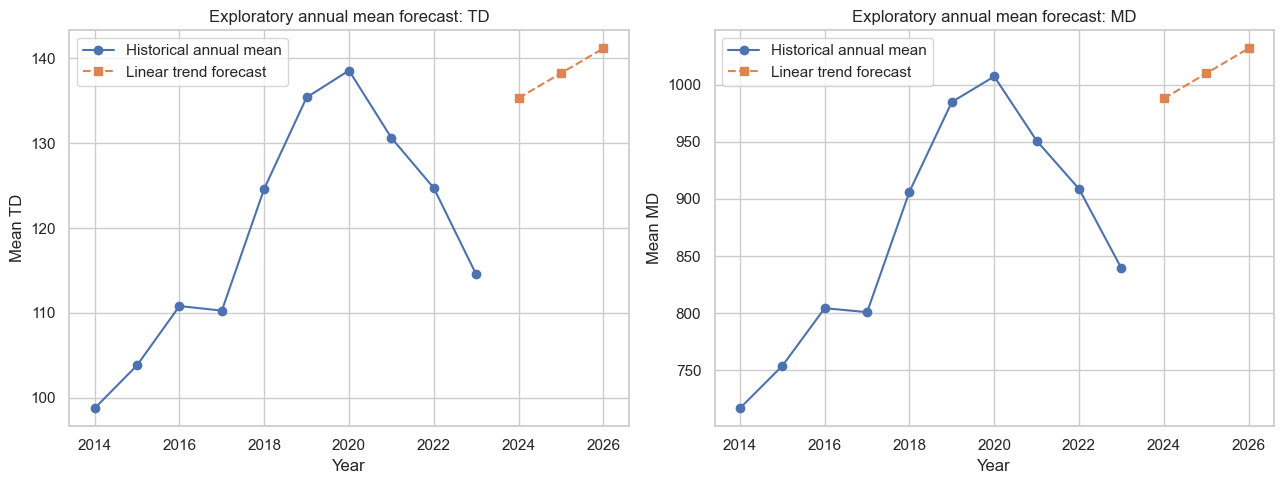

In [20]:
# This is an aggregate trend illustration, separate from the firm-level supervised task.
# With only ~10 yearly points, do not interpret model rankings as reliable evidence.
from sklearn.linear_model import LinearRegression
if {"year", "TD", "MD"}.issubset(df.columns):
    annual = df.groupby("year")[["TD", "MD"]].mean().reset_index()
    future_years = np.arange(int(annual["year"].max()) + 1, int(annual["year"].max()) + 4)
    annual_forecasts = {}
    for target in ["TD", "MD"]:
        model = LinearRegression()
        model.fit(annual[["year"]], annual[target])
        annual_forecasts[target] = model.predict(pd.DataFrame({"year": future_years}))
    forecast_table = pd.DataFrame({"year": future_years, "forecast_mean_TD": annual_forecasts["TD"], "forecast_mean_MD": annual_forecasts["MD"]})
    display(forecast_table)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, target, col in [(axes[0], "TD", "forecast_mean_TD"), (axes[1], "MD", "forecast_mean_MD")]:
        ax.plot(annual["year"], annual[target], marker="o", label="Historical annual mean")
        ax.plot(future_years, forecast_table[col], marker="s", linestyle="--", label="Linear trend forecast")
        ax.set(title=f"Exploratory annual mean forecast: {target}", xlabel="Year", ylabel=f"Mean {target}")
        ax.legend()
    plt.tight_layout(); plt.show()

## 12. Feature importance (tree model)

,feature,importance
9,numeric__log_MD,0.332535
2,numeric__MD,0.268327
1,numeric__TD,0.199968
8,numeric__log_TD,0.161113
10,numeric__TD_share,0.007111
11,numeric__TD_growth,0.006121
12,numeric__MD_growth,0.005778
0,numeric__year,0.003765
7,numeric__GP,0.002604
3,numeric__BDA,0.001018


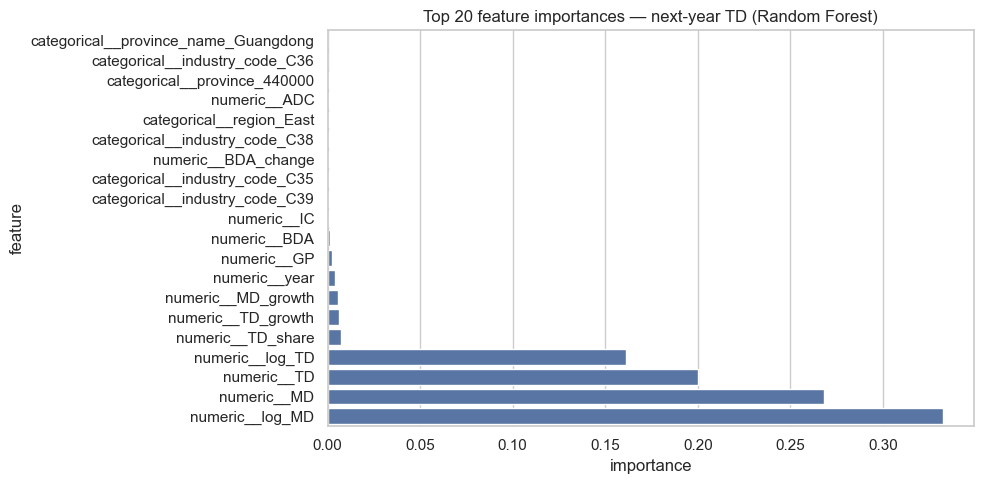

,feature,importance
9,numeric__log_MD,0.416157
2,numeric__MD,0.324601
1,numeric__TD,0.122003
8,numeric__log_TD,0.100207
10,numeric__TD_share,0.006558
11,numeric__TD_growth,0.005685
12,numeric__MD_growth,0.005631
0,numeric__year,0.003737
7,numeric__GP,0.002631
3,numeric__BDA,0.001089


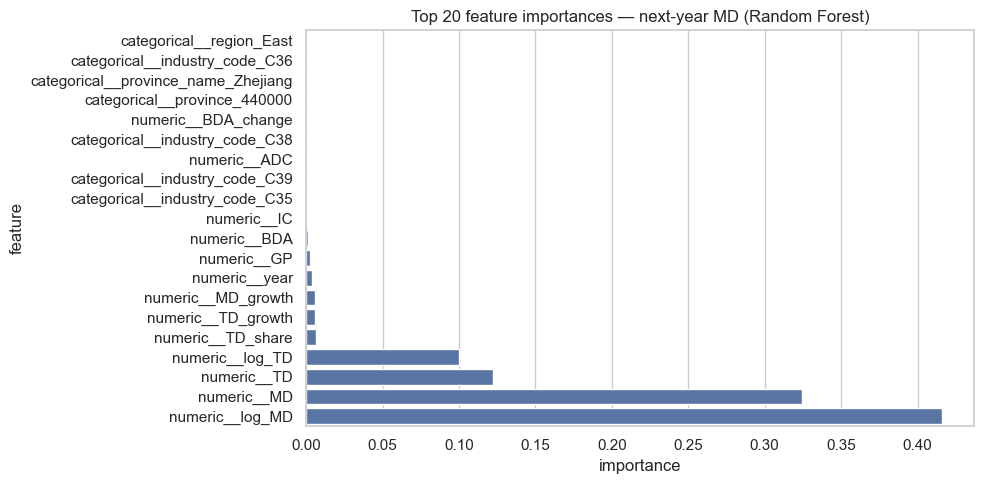

In [21]:
def show_tree_importance(fitted_models, target_label):
    candidates = ["Random Forest", "Extra Trees", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]
    chosen = next((n for n in candidates if n in fitted_models and hasattr(fitted_models[n].named_steps["model"], "feature_importances_")), None)
    if chosen is None:
        print("No fitted tree-based model with feature_importances_ available.")
        return
    pipe = fitted_models[chosen]
    try:
        names = pipe.named_steps["preprocess"].get_feature_names_out()
        importances = pipe.named_steps["model"].feature_importances_
        fi = pd.DataFrame({"feature": names, "importance": importances}).sort_values("importance", ascending=False).head(20)
        display(fi)
        sns.barplot(data=fi.sort_values("importance"), x="importance", y="feature")
        plt.title(f"Top 20 feature importances — {target_label} ({chosen})")
        plt.tight_layout(); plt.show()
    except Exception as exc:
        print("Could not extract feature importance:", exc)

show_tree_importance(fitted_TD or {}, "next-year TD")
show_tree_importance(fitted_MD or {}, "next-year MD")

## 13. Automatic insight summary

In [22]:
print("DATASET SUMMARY")
print(f"• {len(df):,} rows and {df.shape[1]} columns.")
if "firm_code" in df:
    print(f"• {df['firm_code'].nunique():,} distinct firms.")
if "year" in df:
    print(f"• Coverage: {df['year'].min()}–{df['year'].max()}.")
if "region" in df:
    print("• Most represented region:", df["region"].value_counts().idxmax())
if "province_name" in df:
    print("• Most represented province:", df["province_name"].value_counts().idxmax())
if {"TD", "MD"}.issubset(df.columns):
    corr = df[["TD", "MD"]].corr().iloc[0,1]
    print(f"• Pearson correlation between TD and MD: {corr:.4f}. Check whether the indicators are conceptually or mathematically related.")
print("• Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10).rename("missing_count").to_frame())
if not all_results.empty:
    print("• Lowest test RMSE by target:")
    display(all_results.loc[all_results.groupby("target")["RMSE"].idxmin()].sort_values("target"))

DATASET SUMMARY
• 21,203 rows and 26 columns.
• 3,514 distinct firms.
• Coverage: 2014–2023.
• Most represented region: East
• Most represented province: Guangdong
• Pearson correlation between TD and MD: 0.9993. Check whether the indicators are conceptually or mathematically related.
• Missing values by column:


,missing_count
BDA_change,3514
MD_growth,3514
TD_growth,3514
firm_code,0
firm_code_str,0
first_year,0
n_years_observed,0
TD_share,0
log_MD,0
log_TD,0


• Lowest test RMSE by target:


,target,model,MAE,RMSE,R2
18,Next-year MD,Huber Regressor,218.561208,484.943130,0.938515
0,Next-year TD,MLP Neural Network,30.645483,65.974367,0.937854


## 14. How to interpret and improve the results

1. **Use MAE and RMSE together.** MAE is easier to interpret in target units; RMSE penalizes large errors more strongly. R² can be negative on a test set and is not always stable.
2. **Compare against the dummy baseline.** A complex model is only useful if it improves on a simple benchmark.
3. **Check temporal generalization.** The last years are held out. Consider rolling-origin validation for more robust evaluation.
4. **Check target definitions.** Confirm what `TD` and `MD` mean, their units, and whether high values are good or bad.
5. **Inspect data leakage.** Some columns (for example `log_TD`, `TD_share`, `TD_growth`) are derived from current metrics. They are legitimate only if available at the time the forecast would be made. Remove any feature that would not be known operationally.
6. **Avoid causal claims.** Feature importance and correlation show association, not causation.
7. **Panel validation option.** If the real use case is forecasting for firms never seen in training, use a firm-group holdout such as `GroupShuffleSplit` or `GroupKFold`, instead of a time-only split.
8. **Tuning.** Once a shortlist is selected, tune hyperparameters with `TimeSeriesSplit` or year-based validation. Do not tune repeatedly on the final test years.
9. **Model coverage.** The benchmark includes linear, regularized, robust, Bayesian, tree, ensemble, boosting, neighbor, kernel, and neural-network regressors, plus optional XGBoost, LightGBM, and CatBoost. This is a broad practical set, not every possible algorithm.
10. **Classification is not included by default.** If you define a meaningful class target (for example, high vs. low growth using a business-defined threshold), a separate classification workflow with class balance checks, confusion matrix, precision/recall/F1 and ROC-AUC can be added. Avoid arbitrary labels that have no analytical meaning.